In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pwd

/content


In [ ]:
!unzip "/content/drive/MyDrive/yolov8_ANPR.zip" -d /content/yoloV8_dataset

Archive:  /content/drive/MyDrive/yolov8_ANPR.zip
   creating: /content/yoloV8_dataset/archive/
  inflating: /content/yoloV8_dataset/archive/classes.txt  
  inflating: /content/yoloV8_dataset/archive/dataset.yaml  
   creating: /content/yoloV8_dataset/archive/images/
   creating: /content/yoloV8_dataset/archive/images/train/
  inflating: /content/yoloV8_dataset/archive/images/train/0073797c-a755-4972-b76b-8ef2b31d44ab___new_IMG_20160315_071740.jpg.jpg  
  inflating: /content/yoloV8_dataset/archive/images/train/00b42b2c-f193-4863-b92c-0245cbc816da___3e7fd381-0ae5-4421-8a70-279ee0ec1c61_Nissan-Terrano-Petrol-Review-Images-Black-Front-Angle.jpg  
  inflating: /content/yoloV8_dataset/archive/images/train/03273806-bb1e-48da-8c8b-a0133a90197a___2014-Skoda-Yeti-Test-Drive.jpg.jpg  
  inflating: /content/yoloV8_dataset/archive/images/train/0369b20e-b432-4409-90f9-2420877aa386___8151536c79159a1557421da5f27f9f0e.jpg.jpg  
  inflating: /content/yoloV8_dataset/archive/images/train/07064c2c-2aa3-441

In [ ]:
!pip install ultralytics -q
from IPython.display import clear_output
clear_output()

import ultralytics
ultralytics.checks()


Ultralytics 8.3.163 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.0/112.6 GB disk)


In [ ]:
data_yaml = """
path: /content/yoloV8_dataset/archive
train: images/train
val: images/val

names:
  0: license_plate
"""
with open("/content/yoloV8_dataset/archive/dataset.yaml", "w") as f:
    f.write(data_yaml)


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.yaml")
model.train(data="/content/yoloV8_dataset/archive/dataset.yaml", epochs=50, imgsz=640, batch=16)

Ultralytics 8.3.163 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yoloV8_dataset/archive/dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pos

100%|██████████| 755k/755k [00:00<00:00, 22.1MB/s]

Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

YOLOv8n summary: 129 layers, 3,011,043 parameters, 3,011,027 gradients, 8.2 GFLOPs

Freezing layer 'model.22.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...


100%|██████████| 5.35M/5.35M [00:00<00:00, 103MB/s]


...

                   all        169        169      0.999      0.982      0.994      0.854



50 epochs completed in 0.422 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 6.2MB
Optimizer stripped from runs/detect/train/weights/best.pt, 6.2MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.163 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 6/6 [00:02<00:00,  2.32it/s]


                   all        169        169      0.999      0.982      0.994      0.863
Speed: 0.4ms preprocess, 3.5ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to runs/detect/train


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78050c0ec890>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
results = model.predict(source="/content/yoloV8_dataset/archive/images/val/video6_210.jpg", save=True, conf=0.5)


image 1/1 /content/yoloV8_dataset/archive/images/val/video6_210.jpg: 288x640 1 license_plate, 38.3ms
Speed: 2.0ms preprocess, 38.3ms inference, 1.7ms postprocess per image at shape (1, 3, 288, 640)
Results saved to runs/detect/train2


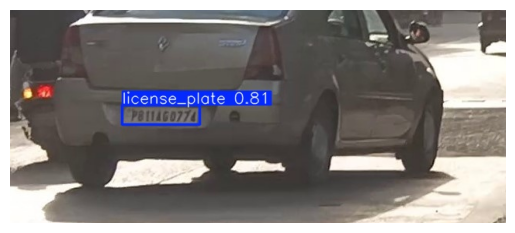

In [ ]:
from matplotlib import pyplot as plt
import matplotlib.image as mpimg

# Replace with your actual path
img_path = "/content/runs/detect/train2/video6_210.jpg"

# Load and display image
img = mpimg.imread(img_path)
plt.imshow(img)
plt.axis('off')  # Hide axes
plt.show()


In [ ]:
import os
from IPython.display import display
from PIL import Image
from ultralytics import YOLO

model = YOLO('/content/runs/detect/train/weights/best.pt')

val_dir = "/content/yoloV8_dataset/archive/images/val"

image_files = [os.path.join(val_dir, f) for f in os.listdir(val_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

for img_path in image_files:
    print(f"\n🔍 Processing: {img_path}")

    results = model.predict(source=img_path, conf=0.5, save=True)

    # result_img = results[0].plot()
    # display(Image.fromarray(result_img))



🔍 Processing: /content/yoloV8_dataset/archive/images/val/video8_920.jpg

image 1/1 /content/yoloV8_dataset/archive/images/val/video8_920.jpg: 544x640 1 license_plate, 14.3ms
Speed: 6.4ms preprocess, 14.3ms inference, 2.7ms postprocess per image at shape (1, 3, 544, 640)
Results saved to runs/detect/predict

🔍 Processing: /content/yoloV8_dataset/archive/images/val/video8_760.jpg

image 1/1 /content/yoloV8_dataset/archive/images/val/video8_760.jpg: 640x512 1 license_plate, 7.3ms
Speed: 2.5ms preprocess, 7.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 512)
Results saved to runs/detect/predict

🔍 Processing: /content/yoloV8_dataset/archive/images/val/video8_1300.jpg

image 1/1 /content/yoloV8_dataset/archive/images/val/video8_1300.jpg: 608x640 1 license_plate, 8.1ms
Speed: 2.9ms preprocess, 8.1ms inference, 1.6ms postprocess per image at shape (1, 3, 608, 640)
Results saved to runs/detect/predict

🔍 Processing: /content/yoloV8_dataset/archive/images/val/video8_1680.jpg



In [ ]:
import os
from matplotlib import pyplot as plt
import matplotlib.image as mpimg

# Folder with predicted/detected images
detected_folder = "/content/runs/detect/predict"

# Get all image paths
image_files = [os.path.join(detected_folder, f) for f in os.listdir(detected_folder)
               if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

image_files.sort()

images_per_row = 3
num_images = len(image_files)
rows = (num_images + images_per_row - 1)

plt.figure(figsize=(18, rows * 4), facecolor='black')

for i, img_path in enumerate(image_files):
    img = mpimg.imread(img_path)

    ax = plt.subplot(rows, images_per_row, i + 1)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(os.path.basename(img_path), fontsize=9, color='white')

    ax.set_facecolor('black')

plt.tight_layout()
plt.show()


In [ ]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 422.8/422.8 kB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 292.9/292.9 kB 26.3 MB/s eta 0:00:00


In [ ]:
import re
import os
import cv2
import easyocr
from ultralytics import YOLO

ocr = easyocr.Reader(['en'])

model = YOLO("/content/runs/detect/train/weights/best.pt")
img_path = "/content/yoloV8_dataset/archive/images/val/video9_80.jpg"

results = model.predict(source=img_path, conf=0.5, save=False)

for result in results:
    boxes = result.boxes.xyxy.cpu().numpy().astype(int)
    image = cv2.imread(img_path)

    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = box
        cropped = image[y1:y2, x1:x2]

        ocr_results = ocr.readtext(cropped)

        if ocr_results:
            for (bbox, text, conf) in ocr_results:
              clean_text = re.sub(r'[^A-Za-z0-9]', '', text)
              if len(clean_text) > 3:
                print(f"🔤 OCR Result: {clean_text} (Confidence: {conf:.2f})")
        else:
            print("⚠️ No OCR result detected.")



image 1/1 /content/yoloV8_dataset/archive/images/val/video9_80.jpg: 384x640 1 license_plate, 8.3ms
Speed: 2.8ms preprocess, 8.3ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)
🔤 OCR Result: MHOIDT1917 (Confidence: 0.62)


In [ ]:
!cp -r /content/runs /content/drive/MyDrive/ANPR_outputs

In [ ]:
!cp -r /content/yoloV8_dataset /content/drive/MyDrive/ANPR_outputs